# Supplementary figures

Supplementary Fig. 2 is drawn here with the same plotting functions (`../benchmarks/fig_panels.py`) and style (`../benchmarks/pub_style.py`) as Figure 1. The others are copied from the analysis that draws them, with their final numbers.

**Supplementary Fig. 2 (accuracy)**: a, alignment bitscore to AF3-derived 3Di, ESM3Di vs ProstT5; b, distributions of 3Di identity to AF3-derived 3Di (dashed lines: medians); c, SCOPe superfamily- and fold-level sensitivity (the fold panel shows the first 10% of queries; the AUC is over all queries).

Data: `../benchmarks/quality/results/3di_benchmark.csv`, `../benchmarks/quality/results/scope_sensitivity.csv`. Output: `supplementary/`.

**Supplementary Figs. 4-7**, from `../experiments/analyses/phylogeny/`: Fig. 4, *Filoviridae* GP trees without X-rich sequences (X ≤ 5%); Fig. 5, *Flaviviridae* E, E1 and E2 trees; Fig. 6, paired jackknife differences of the *Flaviviridae* trees (`flaviviridae/figures/flaviviridae_jackknife_difference`); Fig. 7, metagenomic tree coloured by protein cluster, in the style of Figure 2c (`metagenomic_trees/figures/metagenomic_supplementary.png`, with the entries and colours of its `.svg` legend). **Supplementary Table 1**, pairwise amino-acid identities (`pairwise_identity/results/pairwise_identity.csv`).

**Supplementary Table 2**, polyprotein cleavage-site metrics, from `../experiments/analyses/polyprotein_cut/results/esm3di_vs_esmpp_standardised/supp_table_metrics_formatted.csv`.

The *Filoviridae* GP accession list is no longer a supplementary table; the Methods point to it on Zenodo.

**Supplementary Fig. 3 (runtime vs sequence length)**: drawn here with `plot_runtime_vs_length_end_to_end_and_inference`, marked as Figure 1d (filled: end to end; open: inference only, ESM3Di). Data: `../benchmarks/speed/results/final2_length_bins_plms.csv` (ESM3Di inference only, ProstT5), `final_length_bins_esm3di_cli.csv` (ESM3Di end to end); 512 sequences per length bin.

The speed benchmark against the number of sequences moved to Figure 1d. The NP trees, the GP amino-acid species tree, the earlier jackknife figure and the pairwise identity figure (its table is Supplementary Table 1) are no longer part of the supplement; their analyses and figures stay in `../experiments/analyses/phylogeny/` and `../benchmarks/speed/`.


In [1]:
# Re-import fig_panels/pub_style when they change, without restarting the kernel
%load_ext autoreload
%autoreload 2

import shutil
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "../benchmarks")  # holds the shared figure style and plotting functions
from pub_style import MM, WIDTH_DOUBLE, add_aligned_panel_labels, save_pub, use_pub_style
sys.path.insert(0, "../experiments/analyses/phylogeny/shared")  # the tree drawing of Figure 2c
from fig_panels import (
    BITSCORE_ARGS, plot_identity_density, plot_method_scatter, plot_runtime_vs_length_end_to_end_and_inference,
    plot_scope_level,
)

from tree_plot import (
    HEADING_MM, INK_GRID_MM, TITLE_BASELINE_MM, closest_spot, cropped_tree_image, draw_legend, legend_geometry, mm_canvas, rich_text,
)
from PIL import Image
import numpy as np

use_pub_style()
OUT_DIR = Path("supplementary")
# Same column width and row height as Figure 1, so panels have the same size
COLUMN_WIDTH = WIDTH_DOUBLE / 3
ROW_HEIGHT = 60 * MM

identity_df = pd.read_csv("../benchmarks/quality/results/3di_benchmark.csv")
scope_df = pd.read_csv("../benchmarks/quality/results/scope_sensitivity.csv")
nseq_df = pd.read_csv("../benchmarks/speed/results/final2_nseq.csv")
esm3di_cli_df = pd.read_csv("../benchmarks/speed/results/final2_nseq_esm3di_cli.csv")
length_plm_df = pd.read_csv("../benchmarks/speed/results/final2_length_bins_plms.csv")  # ESM3Di inference only, ProstT5
length_esm3di_cli_df = pd.read_csv("../benchmarks/speed/results/final_length_bins_esm3di_cli.csv")  # ESM3Di end to end

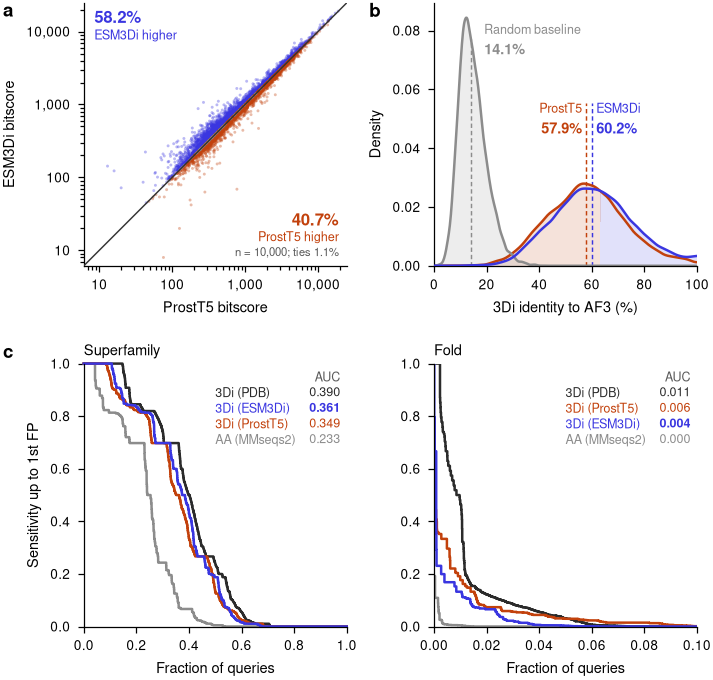

In [2]:
# Supplementary Fig. 2: a, bitscore scatter; b, identity distributions;
# c, SCOPe superfamily and fold (one panel, shared y label)
fig = plt.figure(figsize=(2 * COLUMN_WIDTH, 2 * ROW_HEIGHT), layout="constrained")
grid = fig.add_gridspec(2, 2)
ax_a = fig.add_subplot(grid[0, 0])
ax_b = fig.add_subplot(grid[0, 1])
ax_superfamily = fig.add_subplot(grid[1, 0])
ax_fold = fig.add_subplot(grid[1, 1])

plot_method_scatter(ax_a, identity_df, **BITSCORE_ARGS)
plot_identity_density(ax_b, identity_df)
ax_b.set_box_aspect(1)
plot_scope_level(ax_superfamily, scope_df, "Superfamily")
plot_scope_level(ax_fold, scope_df, "Fold", show_ylabel=False, x_max=0.1)  # all curves end near 0
add_aligned_panel_labels(fig, {"a": ax_a, "b": ax_b, "c": [ax_superfamily, ax_fold]})

save_pub(fig, "supplementary_figure2_accuracy", OUT_DIR)
plt.show()

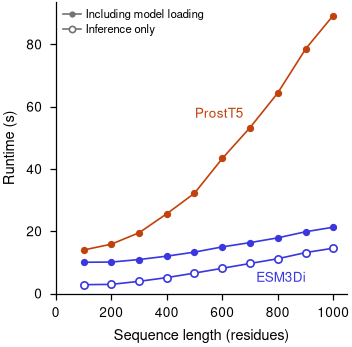

In [3]:
# Supplementary Fig. 3: runtime vs sequence length (512 sequences per bin), marked as Figure 1d:
# filled = end to end (CLI call, including model loading), open = inference only (ESM3Di)
fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, ROW_HEIGHT), layout="constrained")
plot_runtime_vs_length_end_to_end_and_inference(ax, length_plm_df, length_esm3di_cli_df)
save_pub(fig, "supplementary_figure3_runtime_vs_length", OUT_DIR)
plt.show()

tree 100 mm, legend at (73.5, 0.0) mm, covering 0.0 mm2 of ink


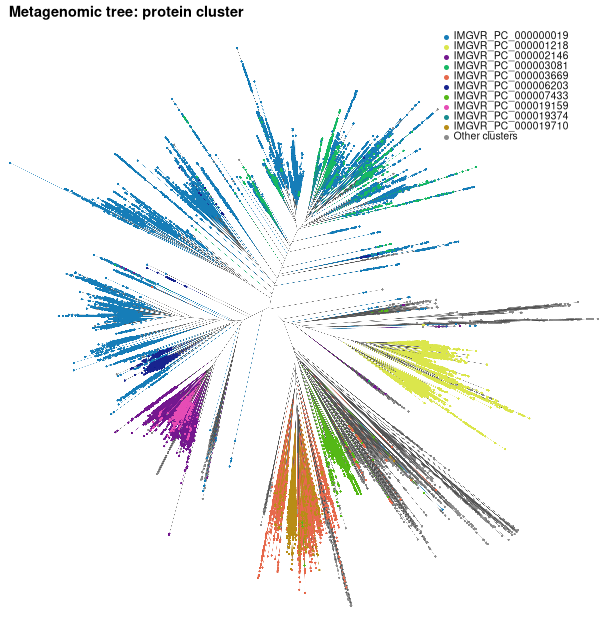

In [4]:
# Supplementary Fig. 7: metagenomic tree coloured by protein cluster, in the style of Figure 2c. The legend repeats the entries
# and colours of metagenomic_supplementary.svg, whose labels are outlines rather than text.
CLUSTER_TREE = Path("../experiments/analyses/phylogeny/metagenomic_trees/figures/metagenomic_supplementary.png")
CLUSTER_LEGEND = [("IMGVR_PC_000000019", "#167DB8"), ("IMGVR_PC_000001218", "#DBE64C"), ("IMGVR_PC_000002146", "#74188F"),
                  ("IMGVR_PC_000003081", "#16B864"), ("IMGVR_PC_000003669", "#E6694C"), ("IMGVR_PC_000006203", "#18248F"),
                  ("IMGVR_PC_000007433", "#55B816"), ("IMGVR_PC_000019159", "#E64CB5"), ("IMGVR_PC_000019374", "#188C8F"),
                  ("IMGVR_PC_000019710", "#B88D16"), ("Other clusters", "#8C8C8C")]
TREE_MM = 100
LEFT_MM = 1            # in line with the heading
LEGEND_ROW_MM = 1.7   # as in Figure 2c

image = cropped_tree_image(CLUSTER_TREE)
blocks = [(None, [entry], False) for entry in CLUSTER_LEGEND]
_, _, legend_width, legend_height = legend_geometry(blocks, 1, row_mm=LEGEND_ROW_MM)
# White space for the legend in the upper right, keeping clear of every tip
cells = int(TREE_MM / INK_GRID_MM)
grid = np.zeros((cells, cells + int((legend_width + 2) / INK_GRID_MM)), bool)
grid[:cells, :cells] = np.asarray(image.resize((cells, cells), Image.Resampling.BOX)).min(axis=2) < 250
grid[:, :cells // 2] = True
grid[cells // 2:] = True
spot, covered = closest_spot(grid, legend_width, legend_height)
print(f"tree {TREE_MM} mm, legend at {spot} mm, covering {covered:.1f} mm2 of ink")

width_mm = LEFT_MM + max(TREE_MM, spot[0] + legend_width) + 1
height_mm = HEADING_MM + TREE_MM + 1
fig = plt.figure(figsize=(width_mm * MM, height_mm * MM))
canvas = mm_canvas(fig, width_mm, height_mm)
rich_text(canvas, 1, TITLE_BASELINE_MM, [("Metagenomic tree: protein cluster", dict(fontweight="bold"))], fontsize=7, va="baseline")
ax = fig.add_axes((LEFT_MM / width_mm, 1 - (HEADING_MM + TREE_MM) / height_mm, TREE_MM / width_mm, TREE_MM / height_mm))
pixels = round(TREE_MM * MM * 600)
ax.imshow(np.asarray(image.resize((pixels, pixels), Image.Resampling.LANCZOS)), interpolation="none")
ax.set_axis_off()
draw_legend(canvas, blocks, LEFT_MM + spot[0], HEADING_MM + spot[1], row_mm=LEGEND_ROW_MM)
with plt.rc_context({"savefig.bbox": "standard"}):
    save_pub(fig, "supplementary_figure7_metagenomic_protein_clusters", OUT_DIR)
plt.show()


In [5]:
# Supplementary Figs. 4, 5 and 6 and Tables 1 and 2: the outputs of the tree analyses, under their final numbers.
# The genus relationships are now numbers on the trees of Figure 2a, and the jackknife a figure of its paired
# differences rather than a table, so neither is a supplementary table any more.
PHYLOGENY = Path("../experiments/analyses/phylogeny")
TREE_FIGURES = {"supplementary_figure4_filoviridae_gp_trees": "filoviridae/figures/filoviridae_gp_filtered_trees",
                "supplementary_figure5_flaviviridae_glycoprotein_trees": "flaviviridae/figures/flaviviridae_glycoprotein_trees",
                "supplementary_figure6_flaviviridae_jackknife": "flaviviridae/figures/flaviviridae_jackknife_difference"}
for name, source in TREE_FIGURES.items():
    for extension in ("pdf", "png"):
        shutil.copyfile(PHYLOGENY / f"{source}.{extension}", OUT_DIR / f"{name}.{extension}")

shutil.copyfile(PHYLOGENY / "pairwise_identity/results/pairwise_identity.csv", OUT_DIR / "supplementary_table1_pairwise_identity.csv")
shutil.copyfile(Path("../experiments/analyses/polyprotein_cut/results/esm3di_vs_esmpp_standardised/supp_table_metrics_formatted.csv"),
                OUT_DIR / "supplementary_table2_polyprotein_cleavage.csv")
sorted(path.name for path in OUT_DIR.iterdir())

['supplementary_figure2_accuracy.pdf',
 'supplementary_figure2_accuracy.png',
 'supplementary_figure3_runtime_vs_length.pdf',
 'supplementary_figure3_runtime_vs_length.png',
 'supplementary_figure4_filoviridae_gp_trees.pdf',
 'supplementary_figure4_filoviridae_gp_trees.png',
 'supplementary_figure5_flaviviridae_glycoprotein_trees.pdf',
 'supplementary_figure5_flaviviridae_glycoprotein_trees.png',
 'supplementary_figure6_flaviviridae_jackknife.pdf',
 'supplementary_figure6_flaviviridae_jackknife.png',
 'supplementary_figure7_metagenomic_protein_clusters.pdf',
 'supplementary_figure7_metagenomic_protein_clusters.png',
 'supplementary_table1_filoviridae_gp_accessions.csv']